**Bangla-Handwritten-CNN-Classification**

**Import Libraries and Check Device**

In [2]:
from pathlib import Path
import torch
from torchvision import datasets, transforms
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

input_dir = Path("/kaggle/input")

dataset_paths = (
    sorted(input_dir.rglob("BPS2025*"))
    + sorted(input_dir.rglob("Processed data"))
)

print("Dataset paths found:", len(dataset_paths))

for path in dataset_paths:
    print(path)
print(list(input_dir.rglob("*.[zZ][iI][pP]")))

Device: cuda
Dataset paths found: 4
/kaggle/input/datasets/newershit/bangla-handwritten-alphabet/BPS2025 A Demographically Focused Dataset of Handw
/kaggle/input/datasets/newershit/bangla-handwritten-alphabet/BPS2025 A Demographically Focused Dataset of Handw/BPS2025_OCR_Bangla_Dataset_Final_V
/kaggle/input/datasets/newershit/bangla-handwritten-alphabet/BPS2025 A Demographically Focused Dataset of Handw/BPS2025_OCR_Bangla_Dataset_Final_V/BPS2025_OCR_Bangla_Dataset_Final_V
/kaggle/input/datasets/newershit/bangla-handwritten-alphabet/BPS2025 A Demographically Focused Dataset of Handw/BPS2025_OCR_Bangla_Dataset_Final_V/BPS2025_OCR_Bangla_Dataset_Final_V/Processed data
[]


**Dataset Path and Image Information**

In [3]:
data_dir = dataset_paths[3]
train_dir = data_dir / "train"

print("Training folder exists:", train_dir.is_dir())
print("Classes:", sorted(folder.name for folder in train_dir.iterdir() if folder.is_dir()))

Training folder exists: True
Classes: ['00', '01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29', '30', '31', '32', '33', '34', '35', '36', '37', '38', '39', '40', '41', '42', '43', '44', '45', '46', '47', '48', '49', '50', '51', '52', '53', '54', '55', '56', '57', '58', '59']


## Visualizing Sample Images

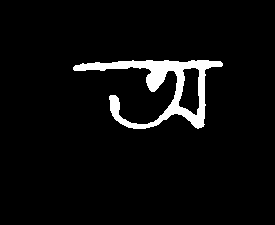

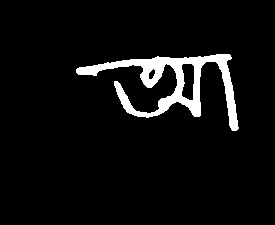

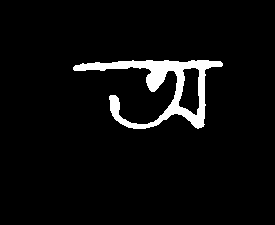

In [4]:
from PIL import Image

class_dir = train_dir / "00"
image_path = next(class_dir.glob("*.png"))
display(Image.open(image_path))



class_dir1=train_dir/'01'

image_path1=next(class_dir1.glob("*.png"))
display(Image.open(image_path1))



class_dir3=train_dir/'03'
image_path3=next(class_dir.glob("*.png"))
display(Image.open(image_path3))

## Checking Image Channels and Dimensions

In [5]:
from torchvision.transforms import ToTensor

with Image.open(image_path) as image:
    image_tensor = ToTensor()(image)

print(image_tensor.shape)

torch.Size([1, 225, 275])


## preprocessing and DataLoaders

In [6]:
from torch import nn
from torch.utils.data import DataLoader

transform_112 = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((112, 137)),
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.5,), std=(0.5,))
])

train_ds_112 = datasets.ImageFolder(data_dir / "train", transform=transform_112)
val_ds_112 = datasets.ImageFolder(data_dir / "validation", transform=transform_112)
test_ds_112 = datasets.ImageFolder(data_dir / "test", transform=transform_112)

batch_size_112 = 32

train_loader_112 = DataLoader(train_ds_112, batch_size=batch_size_112, shuffle=True)
val_loader_112 = DataLoader(val_ds_112, batch_size=batch_size_112, shuffle=False)
test_loader_112 = DataLoader(test_ds_112, batch_size=batch_size_112, shuffle=False)

## Image Preprocessing - 112×137

In [ ]:
from torch import nn

model_112 = nn.Sequential(
    nn.Conv2d(1, 16, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),

    nn.Conv2d(16, 32, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),

    nn.Conv2d(32, 64, kernel_size=3, padding=0),
    nn.ReLU(),
    nn.MaxPool2d(2),

    nn.Flatten(),
    nn.Linear(64 * 13 * 16, 32),
    nn.ReLU(),
    nn.Dropout(0.195),
    nn.Linear(32, len(train_ds_112.classes))
).to(device)



## CNN Architecture - 112×137 with Dropout (0.3)

**Training and Validation Function**

In [11]:
def train_model(model, train_loader, val_loader, epochs=5, lr=0.001,
                checkpoint_path="best_cnn.pt"):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_val_loss = float("inf")

    for epoch in range(epochs):
        # Training
        model.train()
        total_loss, correct, total = 0.0, 0, 0

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            scores = model(images)
            loss = criterion(scores, labels)
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * labels.size(0)
            correct += (scores.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)

        train_loss = total_loss / total
        train_acc = correct / total

        # Validation
        model.eval()
        total_loss, correct, total = 0.0, 0, 0

        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)

                scores = model(images)
                loss = criterion(scores, labels)

                total_loss += loss.item() * labels.size(0)
                correct += (scores.argmax(dim=1) == labels).sum().item()
                total += labels.size(0)

        val_loss = total_loss / total
        val_acc = correct / total

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(model.state_dict(), checkpoint_path)

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        print(f"Epoch {epoch + 1}/{epochs} | "
              f"train loss {train_loss:.4f}, accuracy {train_acc:.1%} | "
              f"val loss {val_loss:.4f}, accuracy {val_acc:.1%}")

    return history

##   train  & val the CNN Model - 112×137

In [12]:
history_112 = train_model(
    model_112,
    train_loader_112,
    val_loader_112,
    epochs=25,
    lr=0.001,
    checkpoint_path="best_cnn_112x137.pt"
)

Epoch 1/25 | train loss 3.5325, accuracy 11.1% | val loss 2.5142, accuracy 30.5%
Epoch 2/25 | train loss 2.2971, accuracy 33.3% | val loss 1.7591, accuracy 48.7%
Epoch 3/25 | train loss 1.8355, accuracy 43.8% | val loss 1.4532, accuracy 57.1%
Epoch 4/25 | train loss 1.5589, accuracy 51.2% | val loss 1.3237, accuracy 61.9%
Epoch 5/25 | train loss 1.3774, accuracy 56.1% | val loss 1.2015, accuracy 64.4%
Epoch 6/25 | train loss 1.2605, accuracy 59.1% | val loss 1.1978, accuracy 64.4%
Epoch 7/25 | train loss 1.1401, accuracy 62.2% | val loss 1.1290, accuracy 67.5%
Epoch 8/25 | train loss 1.0580, accuracy 65.4% | val loss 1.1395, accuracy 67.7%
Epoch 9/25 | train loss 1.0056, accuracy 67.0% | val loss 1.1228, accuracy 67.4%
Epoch 10/25 | train loss 0.9365, accuracy 68.4% | val loss 1.0834, accuracy 68.4%
Epoch 11/25 | train loss 0.8638, accuracy 71.1% | val loss 1.1716, accuracy 67.7%
Epoch 12/25 | train loss 0.8360, accuracy 72.0% | val loss 1.1855, accuracy 69.0%
Epoch 13/25 | train loss 

##   Save the best model

In [ ]:
import os

save_path = "best_model_112.pt"
best_acc = 0

if os.path.exists(save_path):
    best_acc = torch.load(save_path, weights_only=True)["val_acc"]

if val_acc > best_acc:
    torch.save({
        "model": model_112.state_dict(),
        "val_acc": val_acc
    }, save_path)
    print("New best model saved!")
else:
    print("Previous model was better.")

print("Best Accuracy:", round(max(val_acc, best_acc), 2), "%")

## Testing

In [13]:
model_112.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader_112:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model_112(images)
        predicted = outputs.argmax(1)

        correct += (predicted == labels).sum().item()
        total += labels.size(0)

test_acc_112 = correct / total * 100

print("Test Accuracy:", test_acc_112)

Test Accuracy: 69.88000813504169


In [ ]:
print("Best Validation Loss:", min(history_112["val_loss"]))

## Training, Validation, and Testing Accuracy Comparison

****Bangla-Handwritten-CNN-Classification****

In [ ]:
import matplotlib.pyplot as plt

test_acc = test_acc_112 / 100

epochs = range(1, len(history_112["train_loss"]) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

ax1.plot(epochs, history_112["train_loss"], "o-", label="Training")
ax1.plot(epochs, history_112["val_loss"], "o-", label="Validation")
ax1.set(xlabel="Epoch", ylabel="Loss", title="CNN Loss")
ax1.legend()

ax2.plot(epochs, history_112["train_acc"], "o-", label="Training")
ax2.plot(epochs, history_112["val_acc"], "o-", label="Validation")
ax2.plot(epochs[-1], test_acc, "ro", label="Testing")
ax2.set(xlabel="Epoch", ylabel="Accuracy", title="CNN Accuracy")
ax2.legend()

plt.tight_layout()
plt.show()

In [ ]:
print(sum(p.numel() for p in model_112.parameters() if p.requires_grad))

In [ ]:
print(min(history_112["val_loss"]))